# Task 2: Exploratory Data Analysis (EDA)

## 1. Loading the Cleaned Dataset & Restoring Schema

Load `../data/df_clean.csv`, restore `datetime`, `category`, and nullable `Int64` data types lost during CSV serialization, configure plotting defaults, and inspect summary statistics across numeric and categorical features.

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

df_eda = pd.read_csv("../data/df_clean.csv", parse_dates=["date_added"])

for col in ["type", "rating"]:
    df_eda[col] = df_eda[col].astype("category")

for col in ["duration_min", "seasons"]:
    df_eda[col] = df_eda[col].astype("Int64")

print("Dataset shape:", df_eda.shape)
print("\nRestored data types:\n", df_eda.dtypes)
display(df_eda.describe(include="number").T)
display(df_eda.describe(include=["object", "string", "category"]).T)

Dataset shape: (8783, 16)

Restored data types:
 show_id                        str
type                      category
title                          str
director                       str
country                        str
date_added          datetime64[us]
release_year                 int64
rating                    category
duration                       str
listed_in                      str
year_added                   int64
month_added                  int64
duration_min                 Int64
seasons                      Int64
primary_category               str
category_count               int64
dtype: object


,count,mean,std,min,25%,50%,75%,max
release_year,8783.0,2014.18513,8.822944,1925.0,2013.0,2017.0,2019.0,2021.0
year_added,8783.0,2018.873847,1.57411,2008.0,2018.0,2019.0,2020.0,2021.0
month_added,8783.0,6.656382,3.436097,1.0,4.0,7.0,10.0,12.0
duration_min,6121.0,99.572782,28.287142,3.0,87.0,98.0,114.0,312.0
seasons,2662.0,1.75169,1.550947,1.0,1.0,1.0,2.0,17.0
category_count,8783.0,2.19458,0.784185,1.0,2.0,2.0,3.0,3.0


,count,unique,top,freq
show_id,8783,8783,s1,1
type,8783,2,Movie,6121
title,8783,8783,Dick Johnson Is Dead,1
director,6197,4527,Rajiv Chilaka,20
country,8496,85,United States,3239
rating,8783,14,TV-MA,3202
duration,8783,220,1 Season,1790
listed_in,8783,513,"Dramas, International Movies",362
primary_category,8783,36,Dramas,1597


## 2. Content Type Distribution (Movies vs. TV Shows)

Compare the volume and share of `Movies` versus `TV Shows` across the catalog using a summary table and an annotated bar chart.

,type,count,percentage
0,Movie,6121,69.69
1,TV Show,2662,30.31


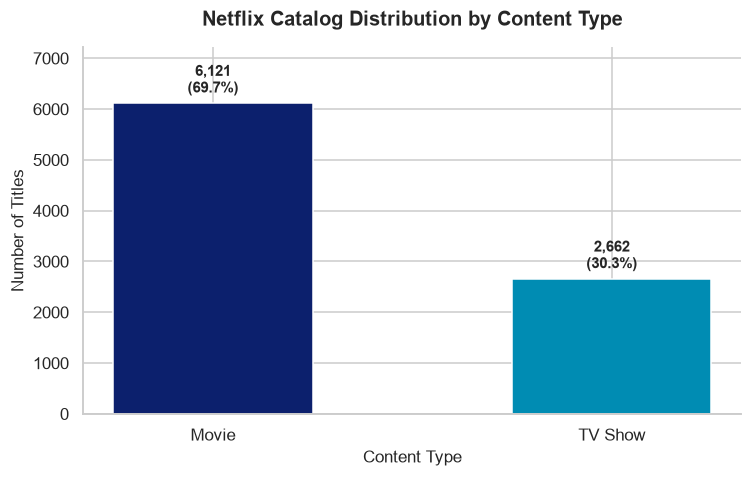

In [52]:
type_summary = (
    df_eda["type"]
    .value_counts()
    .rename_axis("type")
    .reset_index(name="count")
)
type_summary["percentage"] = (
    type_summary["count"] / len(df_eda) * 100
).round(2)
display(type_summary)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    type_summary["type"],
    type_summary["count"],
    color=["#0c206d", "#008cb3"],
    width=0.5,
)

for bar, pct in zip(bars, type_summary["percentage"]):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 120,
        f"{height:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax.set_title(
    "Netflix Catalog Distribution by Content Type",
    fontsize=13,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Content Type", fontsize=11)
ax.set_ylabel("Number of Titles", fontsize=11)
ax.set_ylim(0, type_summary["count"].max() * 1.18)
sns.despine()
plt.tight_layout()
plt.show()

## 3. Content Growth & Temporal Trends

Analyze annual catalog additions by content type (`year_added`), seasonal monthly patterns (`month_added`), and the release-to-addition lag (`year_added - release_year`).

type,Movie,TV Show,Total,TV_Show_Share_%
year_added,,,,
2015,56,26,82,31.7
2016,251,175,426,41.1
2017,836,349,1185,29.5
2018,1234,411,1645,25.0
2019,1422,590,2012,29.3
2020,1284,595,1879,31.7
2021,993,505,1498,33.7


Median release-to-addition lag: 1 year(s)
Added in release year (lag = 0): 37.0%


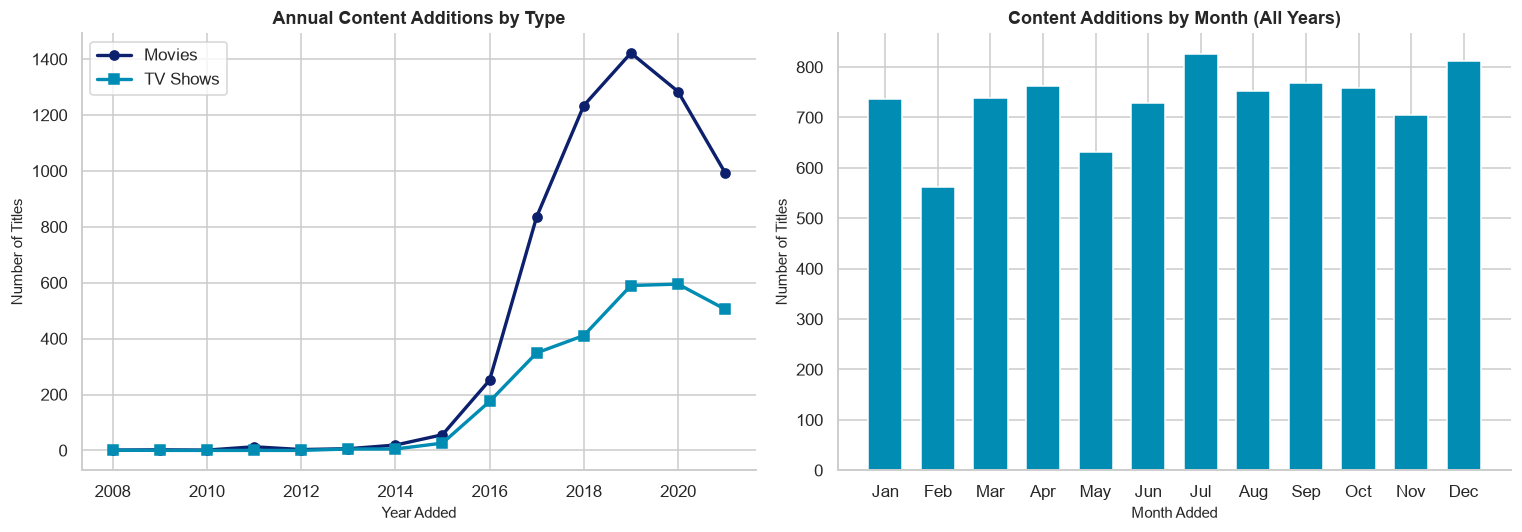

In [53]:
yearly_type = (
    df_eda.groupby(["year_added", "type"], observed=False)
    .size()
    .unstack(fill_value=0)
)
yearly_type["Total"] = yearly_type.sum(axis=1)
yearly_type["TV_Show_Share_%"] = (
    yearly_type["TV Show"] / yearly_type["Total"] * 100
).round(1)
display(yearly_type.tail(7))

monthly_counts = df_eda["month_added"].value_counts().sort_index()

catalog_lag = (df_eda["year_added"] - df_eda["release_year"]).clip(lower=0)
same_year_pct = (catalog_lag == 0).mean() * 100
print(f"Median release-to-addition lag: {catalog_lag.median():.0f} year(s)")
print(f"Added in release year (lag = 0): {same_year_pct:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    yearly_type.index,
    yearly_type["Movie"],
    marker="o",
    linewidth=2.2,
    color="#0c206d",
    label="Movies",
)
axes[0].plot(
    yearly_type.index,
    yearly_type["TV Show"],
    marker="s",
    linewidth=2.2,
    color="#008cb3",
    label="TV Shows",
)
axes[0].set_title(
    "Annual Content Additions by Type", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Year Added", fontsize=10)
axes[0].set_ylabel("Number of Titles", fontsize=10)
axes[0].legend()

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]
axes[1].bar(
    month_labels,
    [monthly_counts.get(m, 0) for m in range(1, 13)],
    color="#008cb3",
    width=0.65,
)
axes[1].set_title(
    "Content Additions by Month (All Years)", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Month Added", fontsize=10)
axes[1].set_ylabel("Number of Titles", fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

### Scope Note: Key Metrics & Step 5 Coverage

The upcoming sections (`Categories & Content Ratings Analysis` and subsequent key metric breakdowns) cover **Step 5** of our workflow by examining core catalog metrics (`listed_in` categories and `rating` distributions) aligned with the assignment's `Key Metrics` and `Summarize findings` stages.

## 4. Geographical Distribution (Top Content-Producing Countries)

Identify the top 10 countries by catalog volume and compare their `Movie` versus `TV Show` composition.

,country,count,share_of_known_%
0,United States,3239,38.12
1,India,1056,12.43
2,United Kingdom,638,7.51
3,Pakistan,420,4.94
4,Canada,271,3.19
5,Japan,259,3.05
6,South Korea,214,2.52
7,France,213,2.51
8,Spain,182,2.14
9,Mexico,138,1.62


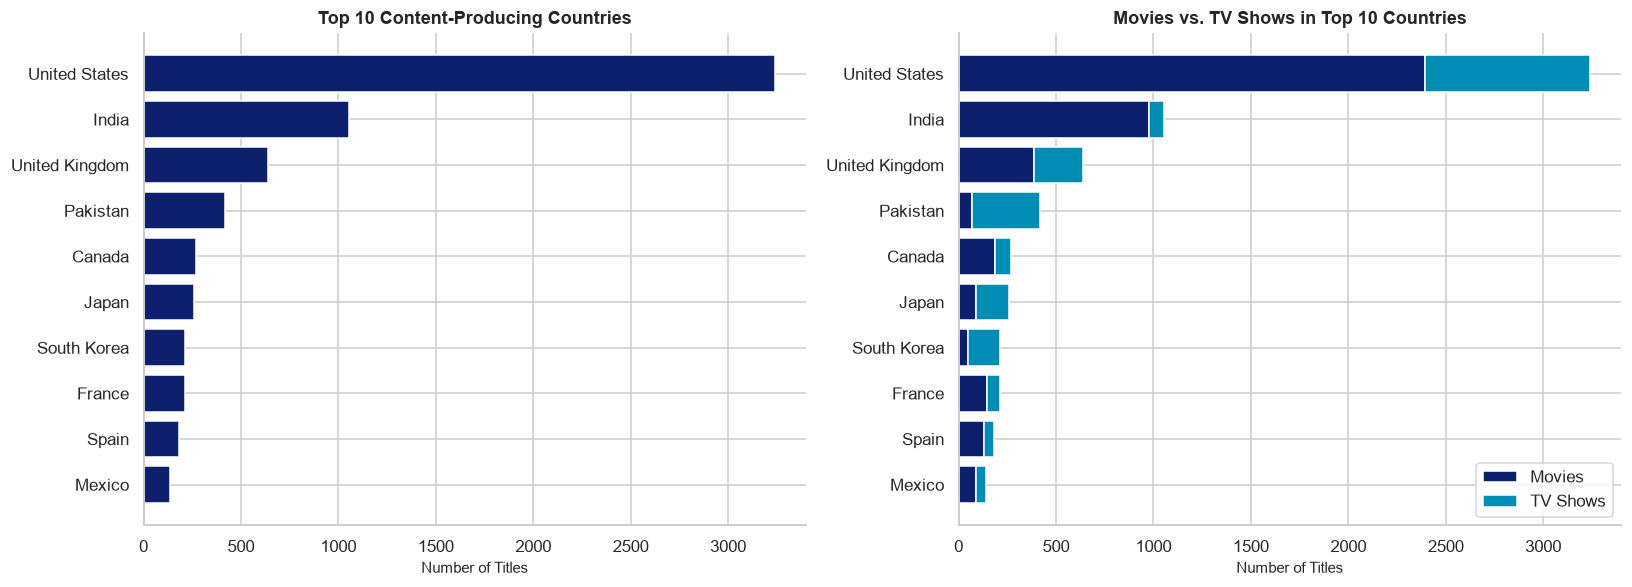

In [54]:
known_countries = df_eda["country"].dropna()
top_countries = (
    known_countries.value_counts()
    .head(10)
    .rename_axis("country")
    .reset_index(name="count")
)
top_countries["share_of_known_%"] = (
    top_countries["count"] / len(known_countries) * 100
).round(2)
display(top_countries)

top10_names = top_countries["country"].tolist()
country_type = (
    df_eda.groupby(["country", "type"], observed=False)
    .size()
    .unstack(fill_value=0)
    .reindex(top10_names, fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].barh(
    top_countries["country"][::-1],
    top_countries["count"][::-1],
    color="#0c206d",
)
axes[0].set_title(
    "Top 10 Content-Producing Countries", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Number of Titles", fontsize=10)

country_type_rev = country_type.iloc[::-1]
axes[1].barh(
    country_type_rev.index,
    country_type_rev["Movie"],
    color="#0c206d",
    label="Movies",
)
axes[1].barh(
    country_type_rev.index,
    country_type_rev["TV Show"],
    left=country_type_rev["Movie"],
    color="#008cb3",
    label="TV Shows",
)
axes[1].set_title(
    "Movies vs. TV Shows in Top 10 Countries", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Number of Titles", fontsize=10)
axes[1].legend()

sns.despine()
plt.tight_layout()
plt.show()

## 5. Categories & Content Ratings Analysis

Identify the top 10 content categories across the catalog and examine how content ratings (`TV-MA`, `TV-14`, `PG-13`, etc.) distribute across `Movies` and `TV Shows`.

In [55]:
x = df_eda["rating"].value_counts().head(8).index.tolist()
x

['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG']

,category,title_appearances,pct_of_titles_%
0,International Movies,2749,31.30
1,Dramas,2422,27.58
2,Comedies,1671,19.03
3,International TV Shows,1347,15.34
4,Documentaries,869,9.89
5,Action & Adventure,859,9.78
6,TV Dramas,760,8.65
7,Independent Movies,755,8.60
8,Children & Family Movies,641,7.30
9,Romantic Movies,616,7.01


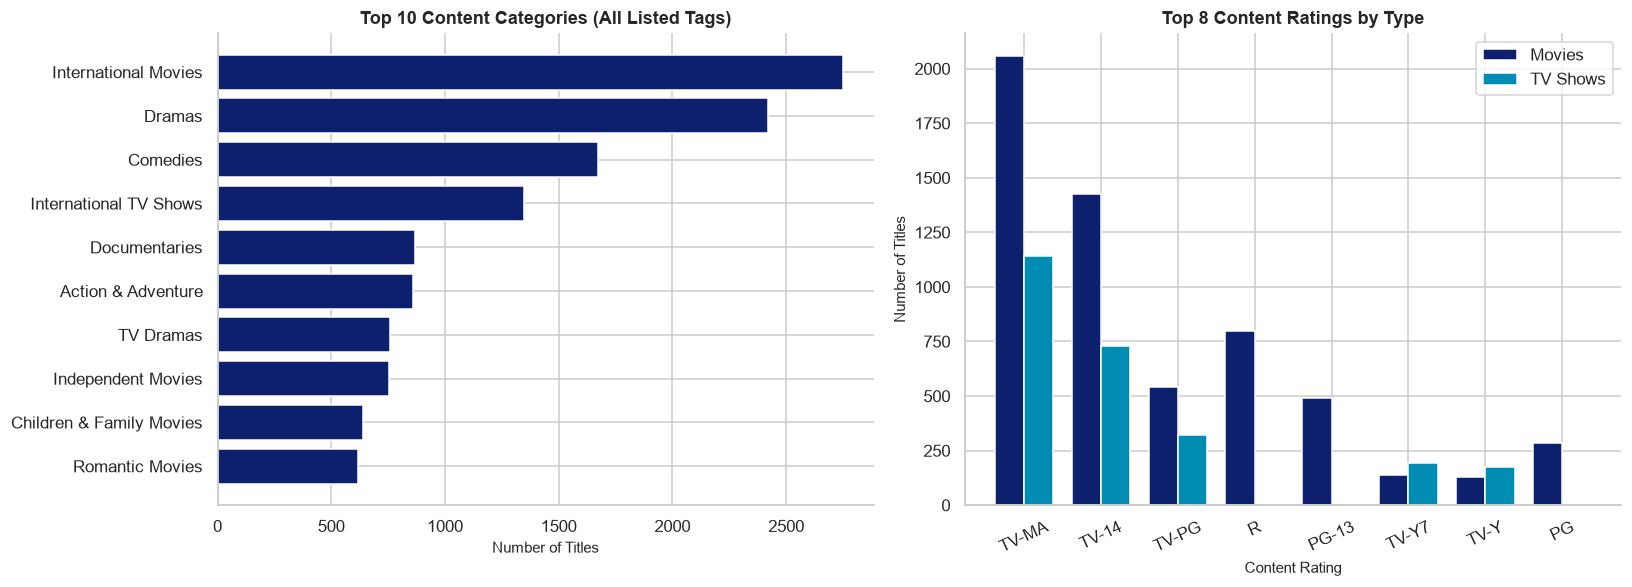

In [56]:
all_categories = (
    df_eda["listed_in"]
    .str.split(",")
    .explode()
    .str.strip()
)
top_categories = (
    all_categories.value_counts()
    .head(10)
    .rename_axis("category")
    .reset_index(name="title_appearances")
)
top_categories["pct_of_titles_%"] = (
    top_categories["title_appearances"] / len(df_eda) * 100
).round(2)
display(top_categories)

top_ratings = df_eda["rating"].value_counts().head(8).index.tolist()
rating_type = (
    df_eda.groupby(["rating", "type"], observed=False)
    .size()
    .unstack(fill_value=0)
    .reindex(top_ratings, fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].barh(
    top_categories["category"][::-1],
    top_categories["title_appearances"][::-1],
    color="#0c206d",
)
axes[0].set_title(
    "Top 10 Content Categories (All Listed Tags)", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Number of Titles", fontsize=10)

x_pos = range(len(rating_type))
width = 0.38
axes[1].bar(
    [x - width / 2 for x in x_pos],
    rating_type["Movie"],
    width=width,
    color="#0c206d",
    label="Movies",
)
axes[1].bar(
    [x + width / 2 for x in x_pos],
    rating_type["TV Show"],
    width=width,
    color="#008cb3",
    label="TV Shows",
)
axes[1].set_xticks(list(x_pos))
axes[1].set_xticklabels(rating_type.index, rotation=25)
axes[1].set_title(
    "Top 8 Content Ratings by Type", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Content Rating", fontsize=10)
axes[1].set_ylabel("Number of Titles", fontsize=10)
axes[1].legend()

sns.despine()
plt.tight_layout()
plt.show()

## 6. Movie Duration, TV Show Seasons & Top Directors

Examine the distribution of movie runtimes (`duration_min`) and TV show season counts (`seasons`), and list the top 10 directors by catalog volume.

Movies duration (min) -> Mean: 99.6, Median: 98.0, Min: 3, Max: 312


,seasons,tv_show_count
0,1,1790
1,2,421
2,3,197
3,4,94
4,5,64
5,6,33
6,7,23
7,8,17


,director,title_count
0,Rajiv Chilaka,20
1,"Raúl Campos, Jan Suter",18
2,Alastair Fothergill,18
3,Suhas Kadav,16
4,Marcus Raboy,16
5,Jay Karas,14
6,Cathy Garcia-Molina,13
7,Youssef Chahine,12
8,Martin Scorsese,12
9,Jay Chapman,12


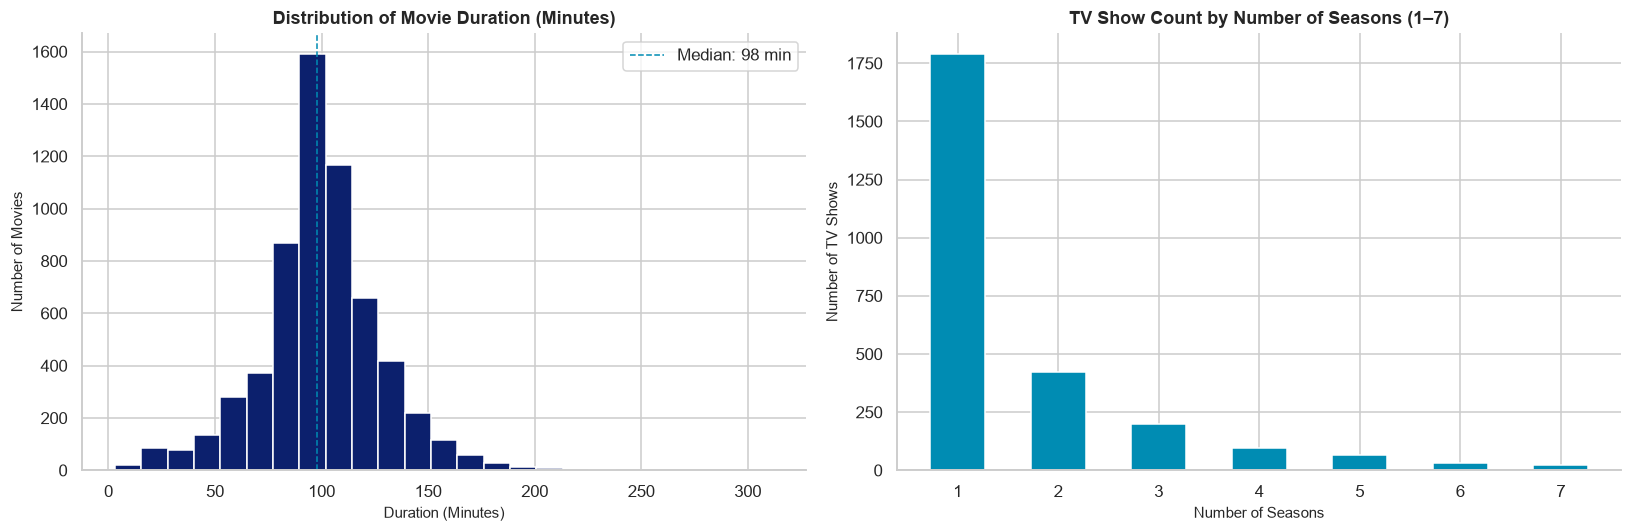

In [ ]:
movie_durations = df_eda["duration_min"].dropna().astype(int)
print(
    f"Movies duration (min) -> Mean: {movie_durations.mean():.1f}, "
    f"Median: {movie_durations.median():.1f}, "
    f"Min: {movie_durations.min()}, Max: {movie_durations.max()}"
)

season_counts = df_eda["seasons"].dropna().astype(int).value_counts().sort_index()
display(
    season_counts.rename_axis("seasons")
    .reset_index(name="tv_show_count")
    .head(8)
)

top_directors = (
    df_eda["director"]
    .dropna()
    .value_counts()
    .head(10)
    .rename_axis("director")
    .reset_index(name="title_count")
)
display(top_directors)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    movie_durations,
    bins=25,
    color="#0c206d",
    edgecolor="white",
)
med_dur = movie_durations.median()
axes[0].axvline(
    med_dur,
    color="#008cb3",
    linestyle="--",
    linewidth=2,
    label=f"Median: {med_dur:.0f} min",
)
axes[0].set_title(
    "Distribution of Movie Duration (Minutes)", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Duration (Minutes)", fontsize=10)
axes[0].set_ylabel("Number of Movies", fontsize=10)
axes[0].legend()

top_seasons = season_counts.head(7)
axes[1].bar(
    top_seasons.index.astype(str),
    top_seasons.values,
    color="#008cb3",
    width=0.55,
)
axes[1].set_title(
    "TV Show Count by Number of Seasons (1–7)", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Number of Seasons", fontsize=10)
axes[1].set_ylabel("Number of TV Shows", fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

## 7. Task 2 Summary & Key Takeaways

- **Catalog Composition & Audience:** Movies represent **69.69%** (`6,121`) of the catalog versus **30.31%** (`2,662`) for TV Shows, with content heavily skewed toward mature audiences (`TV-MA` at `3,202` titles and `TV-14`) and international/drama genres (`International Movies` appearing in `31.30%` of titles, followed by `Dramas` at `27.58%`).
- **Temporal Dynamics & Forecasting Context:** Platform additions surged from **2016** to a peak in **2019** (`2,012` titles), followed by a movie slowdown in **2020–2021** while TV Shows held steady (lifting TV Show share to `33.7%` in `2021`); note that `2021` is a partial year (through September), which is important to keep in mind for future trend forecasting.
- **Geographic, Format & Similarity Signals:** Production is led by the **United States** (`38.12%`), **India** (`12.43%`, predominantly movies), and the **United Kingdom** (`7.51%`), whereas markets like **Pakistan**, **South Korea**, and **Japan** lean strongly toward TV Shows—making `type`, `listed_in`, `country`, `director`, and `rating` informative signals for future content similarity and recommendation modeling.